# Projects - Global Pollution Analysis and Energy Recovery

# Import Libraries

In [115]:
import pandas as pd


# Step: 1 - Data Import and Preprocessing 

`Datasets`


In [116]:
df = pd.read_csv('/Users/shyamalkar/Desktop/ML_project/02_Global_Pollution_Analysis_and_Energy_Recovery/Global_Pollution_Analysis.csv')

`Handling missing values `

In [117]:
df.head()

,Country,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
0,Hungary,2005,272.70,124.27,51.95,94802.83,158.14,5.30,41.11,37078.88,12.56,42.22,20972.96
1,Singapore,2001,86.72,60.34,117.22,56283.92,498.04,6.34,36.44,33128.20,5.23,137.25,34850.41
2,Romania,2016,91.59,83.36,121.72,56256.02,489.51,49.69,9.38,18803.46,13.15,124.47,57773.15
3,Cook Islands,2018,280.61,67.16,93.58,74864.73,145.18,8.91,18.97,9182.27,0.78,67.80,21837.51
4,Djibouti,2008,179.16,127.53,121.55,76862.06,40.38,14.93,34.00,39235.12,12.84,186.52,41379.37


In [118]:
d = df['Air_Pollution_Index'].unique()
print(len(d))

198


In [119]:
df.isnull().sum() # checking missing value count


Country                                   0
Year                                      0
Air_Pollution_Index                       0
Water_Pollution_Index                     0
Soil_Pollution_Index                      0
Industrial_Waste (in tons)                0
Energy_Recovered (in GWh)                 0
CO2_Emissions (in MT)                     0
Renewable_Energy (%)                      0
Plastic_Waste_Produced (in tons)          0
Energy_Consumption_Per_Capita (in MWh)    0
Population (in millions)                  0
GDP_Per_Capita (in USD)                   0
dtype: int64

In [120]:
df.dtypes

Country                                       str
Year                                        int64
Air_Pollution_Index                       float64
Water_Pollution_Index                     float64
Soil_Pollution_Index                      float64
Industrial_Waste (in tons)                float64
Energy_Recovered (in GWh)                 float64
CO2_Emissions (in MT)                     float64
Renewable_Energy (%)                      float64
Plastic_Waste_Produced (in tons)          float64
Energy_Consumption_Per_Capita (in MWh)    float64
Population (in millions)                  float64
GDP_Per_Capita (in USD)                   float64
dtype: object

In [121]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[['Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index']] = scaler.fit_transform(
        df[['Air_Pollution_Index',
            'Water_Pollution_Index',
            'Soil_Pollution_Index']]
)

In [122]:
# Encode Country
#  If Country is categorical and there isn't a meaningful numerical order, One-Hot Encoding is generally preferable:

#df = pd.get_dummies(
#    df,
#    columns=['Country'],
#    drop_first=True
#)

In [123]:
df['Year'] = df['Year'].astype(int)

In [124]:
print(pd.DataFrame(df.columns))

                                         0
0                                  Country
1                                     Year
2                      Air_Pollution_Index
3                    Water_Pollution_Index
4                     Soil_Pollution_Index
5               Industrial_Waste (in tons)
6                Energy_Recovered (in GWh)
7                    CO2_Emissions (in MT)
8                     Renewable_Energy (%)
9         Plastic_Waste_Produced (in tons)
10  Energy_Consumption_Per_Capita (in MWh)
11                Population (in millions)
12                 GDP_Per_Capita (in USD)


# Step 2 - Exploratory Data Analysis 

In [125]:
# 1. Descriptive Statistics
# Calculate descriptive statistics for numerical features like CO2_Emissions and Industrial_Waste_in_tons.
# Select important numerical columns
numerical_columns = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index',
    'Industrial_Waste (in tons)',
    'Energy_Recovered (in GWh)',
    'CO2_Emissions (in MT)',
    'Renewable_Energy (%)',
    'Plastic_Waste_Produced (in tons)',
    'Energy_Consumption_Per_Capita (in MWh)',
    'Population (in millions)',
    'GDP_Per_Capita (in USD)'
]

# Generate descriptive statistics
df[numerical_columns].describe()

,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
count,2.000000e+02,2.000000e+02,2.000000e+02,200.00000,200.000000,200.000000,200.000000,200.000000,200.00000,200.000000,200.000000
mean,7.549517e-17,-3.552714e-16,2.486900e-16,52891.68150,260.448700,24.878100,27.799700,24492.893550,9.43575,104.271300,35307.602400
std,1.002509e+00,1.002509e+00,1.002509e+00,27224.49169,147.141923,14.470892,12.361879,14421.356002,5.57567,56.906574,19481.714455
min,-1.947928e+00,-1.768540e+00,-1.650240e+00,1019.37000,11.730000,1.920000,5.040000,542.950000,0.53000,2.320000,1298.700000
25%,-6.823730e-01,-8.536990e-01,-8.989775e-01,31201.97250,118.355000,11.220000,17.700000,12843.882500,4.58250,60.960000,19525.020000
50%,4.122312e-02,-5.821733e-02,5.332837e-02,55299.15000,273.140000,25.355000,29.170000,24121.540000,9.22500,104.965000,35043.325000
75%,8.489305e-01,8.935479e-01,8.265007e-01,74805.82500,384.957500,38.550000,37.072500,36516.232500,13.99750,150.930000,51629.547500
max,1.753566e+00,1.775151e+00,1.837213e+00,99739.36000,499.980000,49.690000,49.560000,49852.280000,19.98000,198.820000,69143.140000


In [126]:
# Correlation analysis 
# Calculate correlation between numerical features
correlation_matrix = df[numerical_columns].corr()

# Display the correlation matrix
correlation_matrix

,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
Air_Pollution_Index,1.000000,-0.022540,0.036020,0.033252,0.002997,-0.038179,0.011301,-0.018517,-0.053284,-0.028884,-0.069371
Water_Pollution_Index,-0.022540,1.000000,-0.020505,0.126092,-0.041828,-0.002979,-0.056183,0.044215,-0.001960,0.239446,-0.019975
Soil_Pollution_Index,0.036020,-0.020505,1.000000,0.026609,0.064076,0.041913,-0.077602,0.129932,-0.023043,-0.100273,0.115521
Industrial_Waste (in tons),0.033252,0.126092,0.026609,1.000000,-0.161309,-0.060737,-0.149251,0.066844,0.017323,-0.030398,0.061563
Energy_Recovered (in GWh),0.002997,-0.041828,0.064076,-0.161309,1.000000,0.024758,0.043533,-0.072946,-0.030284,-0.075100,0.004535
CO2_Emissions (in MT),-0.038179,-0.002979,0.041913,-0.060737,0.024758,1.000000,-0.038888,0.065154,-0.011750,0.020784,0.029267
Renewable_Energy (%),0.011301,-0.056183,-0.077602,-0.149251,0.043533,-0.038888,1.000000,-0.125175,0.040398,-0.008378,-0.221096
Plastic_Waste_Produced (in tons),-0.018517,0.044215,0.129932,0.066844,-0.072946,0.065154,-0.125175,1.000000,-0.021884,-0.029782,0.090283
Energy_Consumption_Per_Capita (in MWh),-0.053284,-0.001960,-0.023043,0.017323,-0.030284,-0.011750,0.040398,-0.021884,1.000000,0.040493,0.137791
Population (in millions),-0.028884,0.239446,-0.100273,-0.030398,-0.075100,0.020784,-0.008378,-0.029782,0.040493,1.000000,-0.004091


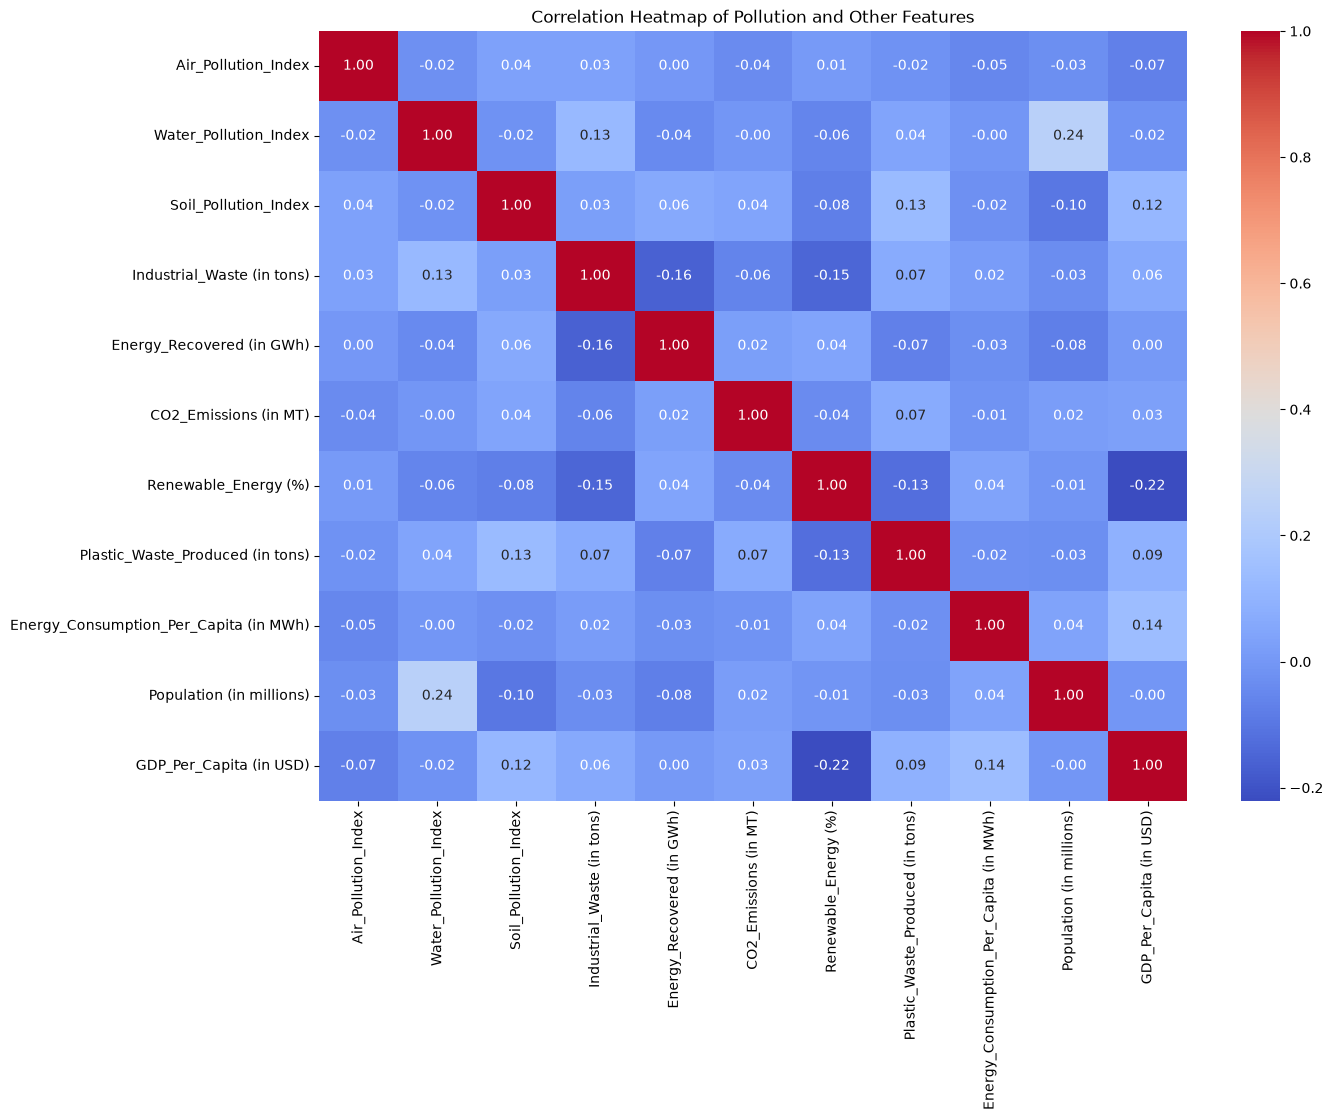

In [127]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create correlation matrix
correlation_matrix = df[numerical_columns].corr()

# Create figure
plt.figure(figsize=(14, 10))

# Create heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

# Add title
plt.title('Correlation Heatmap of Pollution and Other Features')

# Display plot
plt.show()

In [128]:
df.columns

Index(['Country', 'Year', 'Air_Pollution_Index', 'Water_Pollution_Index',
       'Soil_Pollution_Index', 'Industrial_Waste (in tons)',
       'Energy_Recovered (in GWh)', 'CO2_Emissions (in MT)',
       'Renewable_Energy (%)', 'Plastic_Waste_Produced (in tons)',
       'Energy_Consumption_Per_Capita (in MWh)', 'Population (in millions)',
       'GDP_Per_Capita (in USD)'],
      dtype='str')

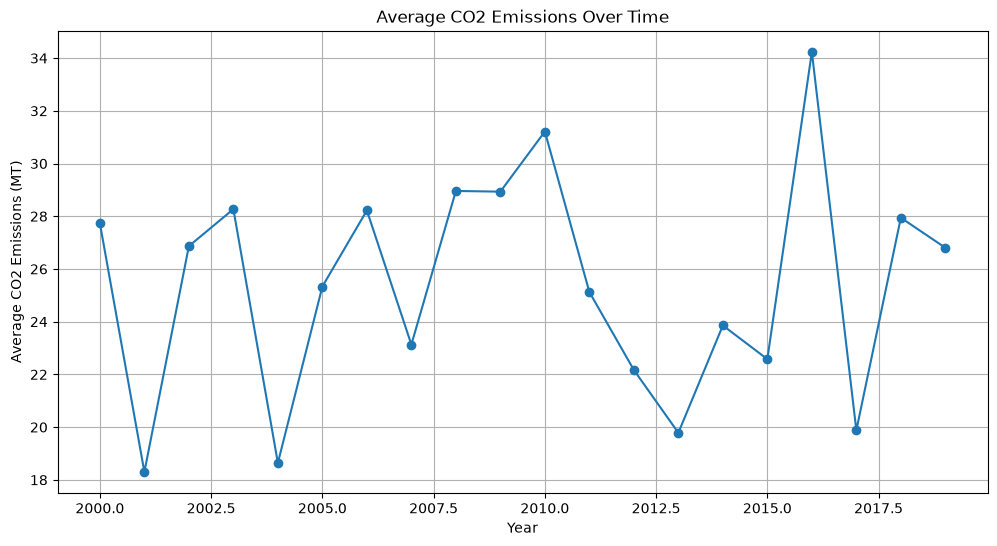

In [133]:
# Calculate average CO2 emissions for each year
yearly_co2 = (
    df.groupby('Year')['CO2_Emissions (in MT)']
    .mean()
)

# Create line plot
plt.figure(figsize=(12, 6))

yearly_co2.plot(kind='line', marker='o')

plt.title('Average CO2 Emissions Over Time')
plt.xlabel('Year')
plt.ylabel('Average CO2 Emissions (MT)')
plt.grid(True)

plt.show()

# Box plot

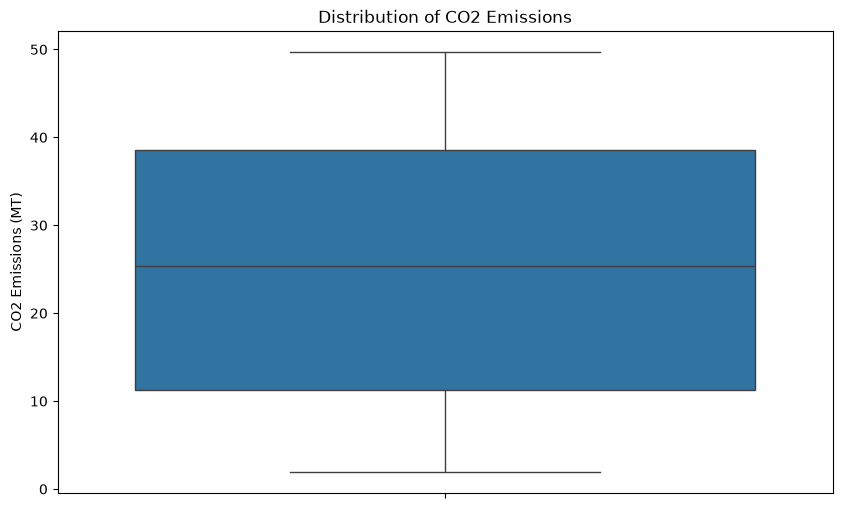

In [134]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    y=df['CO2_Emissions (in MT)']
)

plt.title('Distribution of CO2 Emissions')
plt.ylabel('CO2 Emissions (MT)')

plt.show()

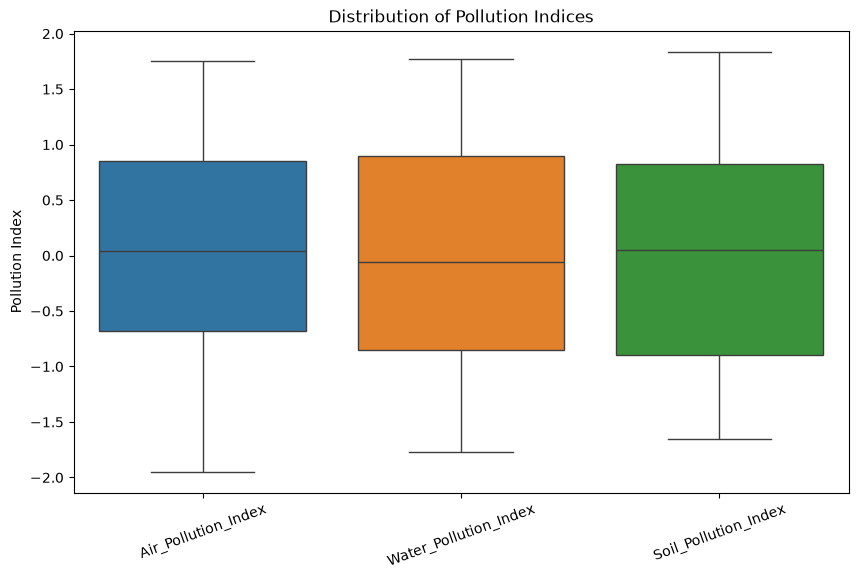

In [135]:
pollution_columns = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index'
]

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[pollution_columns])

plt.title('Distribution of Pollution Indices')
plt.ylabel('Pollution Index')

plt.xticks(rotation=20)

plt.show()

# Step 3:- Feature Engineering 

In [138]:
df['Year_Trend'] = df['Year'] - df['Year'].min()

# Phase 2: Predictive Modeling 

In [139]:
# Import libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


# Select features
features = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index',
    'Industrial_Waste (in tons)',
    'CO2_Emissions (in MT)',
    'Renewable_Energy (%)',
    'Plastic_Waste_Produced (in tons)',
    'Energy_Consumption_Per_Capita (in MWh)',
    'Population (in millions)',
    'GDP_Per_Capita (in USD)',
    'Year_Trend'
]

X = df[features]

# Select target
y = df['Energy_Recovered (in GWh)']


# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# Create Linear Regression model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)


# Make predictions
y_pred = model.predict(X_test)


# Evaluate model
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)


print("R² Score:", r2)
print("MSE:", mse)
print("MAE:", mae)

R² Score: -0.14609246125448783
MSE: 27715.079031943187
MAE: 145.979347230461


In [137]:
df.columns

Index(['Country', 'Year', 'Air_Pollution_Index', 'Water_Pollution_Index',
       'Soil_Pollution_Index', 'Industrial_Waste (in tons)',
       'Energy_Recovered (in GWh)', 'CO2_Emissions (in MT)',
       'Renewable_Energy (%)', 'Plastic_Waste_Produced (in tons)',
       'Energy_Consumption_Per_Capita (in MWh)', 'Population (in millions)',
       'GDP_Per_Capita (in USD)'],
      dtype='str')

In [140]:
pollution_columns = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index'
]

df['Pollution_Score'] = df[pollution_columns].mean(axis=1)

In [141]:
df['Pollution_Severity'] = pd.qcut(
    df['Pollution_Score'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

# Select Features 

In [142]:
features = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index',
    'CO2_Emissions (in MT)'
]

X = df[features]
y = df['Pollution_Severity']

`Train / Test / Split`

In [143]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

`Train Logistics Regression`

In [144]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [145]:
y_pred = model.predict(X_test)


In [146]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.95
Precision: 0.9566666666666667
Recall   : 0.95
F1 Score : 0.9497023809523808


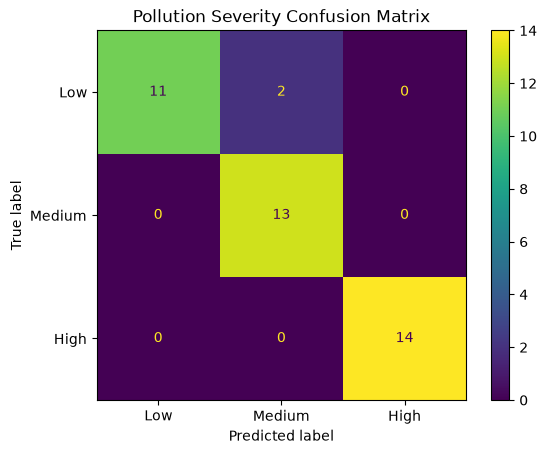

In [147]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Low', 'Medium', 'High']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot()

plt.title('Pollution Severity Confusion Matrix')
plt.show()

# Model Evaluation and Comparison

`Linear regression report`

In [148]:
print("Linear Regression Performance")
print("--------------------------------")
print("R² Score :", r2)
print("MSE      :", mse)
print("MAE      :", mae)

Linear Regression Performance
--------------------------------
R² Score : -0.14609246125448783
MSE      : 27715.079031943187
MAE      : 145.979347230461


`Logistic regression classification report `

In [150]:
from sklearn.metrics import classification_report

print("Logistic Regression Performance")
print(classification_report(y_test, y_pred))

Logistic Regression Performance
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        14
         Low       1.00      0.85      0.92        13
      Medium       0.87      1.00      0.93        13

    accuracy                           0.95        40
   macro avg       0.96      0.95      0.95        40
weighted avg       0.96      0.95      0.95        40



`Confusion Matrix`

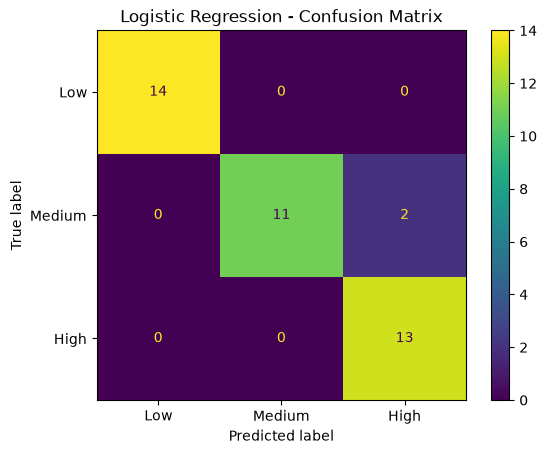

In [151]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Low', 'Medium', 'High']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

# Actionable insights 

In [152]:
country_pollution = (
    df.groupby('Country')['Pollution_Score']
    .mean()
    .sort_values(ascending=False)
)

print(country_pollution.head(10))

Country
Central African Republic    1.136574
Saint Barthelemy            1.109822
Bolivia                     1.096571
Christmas Island            1.027185
Argentina                   0.974645
India                       0.965200
Saint Lucia                 0.953265
Philippines                 0.952476
Papua New Guinea            0.948803
Morocco                     0.936383
Name: Pollution_Score, dtype: float64


# Find Contries with low energy recorvery 

In [153]:
country_energy = (
    df.groupby('Country')['Energy_Recovered (in GWh)']
    .mean()
    .sort_values()
)

print(country_energy.head(10))

Country
Christmas Island    22.21
Zimbabwe            22.84
Colombia            24.45
Malta               28.87
Pakistan            29.23
Saint Helena        36.98
Djibouti            40.38
Tokelau             43.23
Israel              48.94
Denmark             51.80
Name: Energy_Recovered (in GWh), dtype: float64


In [155]:
# Find countries that may benefit most from improvement

country_analysis = df.groupby('Country').agg({
    'Pollution_Score': 'mean',
    'Energy_Recovered (in GWh)': 'mean'
})

priority_countries = country_analysis.sort_values(
    ['Pollution_Score', 'Energy_Recovered (in GWh)'],
    ascending=[False, True]
)

print(priority_countries.head(10))

                          Pollution_Score  Energy_Recovered (in GWh)
Country                                                             
Central African Republic         1.136574                     499.98
Saint Barthelemy                 1.109822                     390.35
Bolivia                          1.096571                      93.73
Christmas Island                 1.027185                      22.21
Argentina                        0.974645                     455.69
India                            0.965200                     199.86
Saint Lucia                      0.953265                     120.87
Philippines                      0.952476                     232.33
Papua New Guinea                 0.948803                     333.14
Morocco                          0.936383                     355.02


# Final Report 



This project analyzed global pollution, waste, energy, and economic data using machine learning. Exploratory Data Analysis identified pollution patterns, country-level differences, yearly trends, correlations, and potential outliers. Feature engineering created a yearly trend and overall pollution score. Linear Regression was used to predict energy recovery based on pollution, waste, emissions, and economic features, evaluated using R², MSE, and MAE. Logistic Regression classified observations into Low, Medium, and High pollution categories using accuracy, precision, recall, F1-score, and a confusion matrix. The analysis suggests reducing industrial waste, increasing renewable energy, improving energy efficiency, and expanding suitable waste-to-energy recovery systems.